# Workshop 2 — Customer concentration: from EDA to credible validation
**Business Intelligence · Moisés Medina and Ignacia Castillo · 20 October 2026**

This notebook is the primary W2 submission. Its question remains: **how much eligible recorded purchase value comes from the highest-value 10% of identifiable customers, and how much value is outside that ranking because an ID is missing?** Our proposed user is a commercial analyst reviewing a historical customer portfolio. The proposed action is to examine major accounts together with the ID-capture process. This is not a claim about the anonymous retailer's actual strategy.

The team reports **100/100 in C1**; no specific instructor correction text was supplied for W2. We therefore label the following new checks and clarifications as **self-audits or W2 extensions**, rather than inventing negative feedback. Preserved W1/C1 artifacts are under `assessments/`.

The specific W2 brief takes precedence over the old calendar: its deadline is **29 October 2026, 23:59, Chile**. The brief prints 22 October as its release date; we do not use that header to invent a work date. This notebook develops the existing descriptive project and fits no predictive model.

## 1. Reproducible setup and prespecified protocol
Run all cells in order. The seed and temporal boundaries are fixed before generating W2 tables. Input data and outputs are project-relative. The protocol records prior W1/C1 exposure to the complete period; freezing this procedure does not erase that exposure.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/w2_analysis.py').exists())
sys.path.insert(0, str(ROOT/'src'))
import w2_analysis as w2
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 105)
protocol = w2.freeze_protocol()
display(pd.DataFrame([{'seed':protocol['seed'], 'source_start':protocol['case_start'],
                      'source_end_exclusive':protocol['case_end_exclusive'],
                      'protocol_sha256':protocol['protocol_sha256']}]))
print('Python:', platform.python_version())
print(json.dumps(protocol['split_dates'], indent=2))

,seed,source_start,source_end_exclusive,protocol_sha256
0,4232026,2010-12-01,2011-12-01,7081b76da0aa89f20ad9274d76beb5dc56ce5b02959ffd8e0c49a1a5fe3e4a09


Python: 3.12.5
{
  "train": [
    "2010-12-01",
    "2011-08-01"
  ],
  "validation": [
    "2011-08-01",
    "2011-10-01"
  ],
  "test": [
    "2011-10-01",
    "2011-12-01"
  ]
}


## 2. Source, observation units and unchanged KPI
UCI Online Retail (Daqing Chen, 2015; DOI **10.24432/C5BW33**, CC BY 4.0) contains 541,909 invoice-line records from 1 December 2010 to 9 December 2011. Our preserved case extract includes **all 516,384 source lines from December 2010 through November 2011**. Only the final incomplete December 2011 was omitted in W1. December 2010 and November 2011 are complete calendar months within the source bounds. Their row counts need not be equal. Complete calendar coverage does not prove that the operational system captured every real transaction.

One source row is an **item entry on an invoice**. Several lines form one invoice; several invoices can be linked to one CustomerID. A C-prefixed invoice is a cancellation record under UCI's dictionary, without a verified link to an original purchase. `Country` is a country label recorded on the line, not a verified delivery destination.

The baseline purchase measure uses positive Quantity, positive UnitPrice, a non-C invoice and a provisional merchandise-code pattern of five digits with an optional final letter. Eligible line value is `Quantity × UnitPrice` in GBP. Original lines remain in the prepared dataset; rows outside these conditions are outside the measure, not silently deleted.

For known IDs, aggregate eligible purchase value over the stated window, rank descending and let **N** be the number of known IDs. **K10 = value of top ceil(0.10N) IDs / all known-ID value × 100.** The number is rounded upward to whole IDs; ties are ordered by ID for reproducibility. **ID coverage = known-ID eligible value / all eligible purchase value × 100.** It is value coverage, not the percentage of rows identified. Neither quantity is audited net revenue, profit, loyalty or lifetime value.

The uncleaned extract has a SHA-256 checked against the retained manifest before preparation. Unavailable line values are left undefined outside the positive-purchase scope; they are not recorded zeros.

In [2]:
raw, data = w2.load_and_prepare()
display(pd.DataFrame({'field':raw.columns,'dtype':raw.dtypes.astype(str).to_numpy()}))
display(raw.head(3))
print('Source rows:',len(raw),'Prepared rows:',len(data))
dictionary = w2.dictionary()
display(dictionary)

,field,dtype
0,InvoiceNo,string
1,StockCode,string
2,Description,string
3,Quantity,int64
4,InvoiceDate,datetime64[ns]
5,UnitPrice,float64
6,CustomerID,Int64
7,Country,string


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom


Source rows: 516384 Prepared rows: 516384


,variable,meaning_and_unit,expected_type,acceptable_values,missing_meaning
0,InvoiceNo,Invoice identifier; C prefix marks a cancellation record,string,Nonblank; repeats across item lines,Not expected; cannot identify invoice if absent
1,StockCode,"Source item/special-code identifier, not commercial category",string,Nonblank; merchandise-pattern rule is provisional,Not expected; flag rather than invent item
2,Description,Recorded item description,nullable string,Free text; not a key,Unknown/unrecorded description; not proof of zero activity
3,Quantity,Signed units on an invoice line,integer,Positive purchase; negative C record; other signs flagged,Not expected; cannot calculate line value
4,InvoiceDate,Recorded invoice-line timestamp,datetime,2010-12-01 <= date < 2011-12-01,Not expected; cannot assign period
5,UnitPrice,Recorded unit price in GBP,numeric,Positive for value measure; zero/negative retained outside it,Not expected; no price imputation
6,CustomerID,Identifier linking recorded lines to a customer account,nullable integer,Positive identifier; not a continuous measurement,Unidentified purchase; no ID imputation
7,Country,Customer country recorded on this line,string,Source labels; UK share uses row label,Meaning unknown if absent; not delivery destination
8,source_row,"Stable position in unchanged case CSV, starting at 1",integer,"Unique, 1..516384",Not permitted; not a source transaction ID
9,eligible_purchase,Matches all baseline purchase conditions,boolean,True/False,Not permitted


## 3. Executable quality checks, treatments and feedback-to-action
`PASS` means the checked violation was absent. `FLAG` identifies observed exceptions, not an automatic deletion or proof of invalid records. Structural violations stop execution; scoped exceptions remain visible with their treatment. Flags overlap and must not be subtracted as a row-flow diagram. The row groups are mutually exclusive.

Missing IDs are retained in total eligible value but omitted from customer ranking. Missing descriptions alone do not invalidate a priced purchase. We do not replace zero/negative prices with another month's price: doing so would invent a positive charge, and the reason for the recorded price is not available. Exact repeats remain in the baseline because no unique source-line ID proves them accidental. Product-code exceptions stay auditable and are examined through sensitivity.

The following exception tables inspect two additional assumptions: whether every invoice has one timestamp, and whether an ID has one stable country label. We use minimum/maximum invoice times to check boundaries without rewriting source timestamps. Country proportions use recorded line value rather than forcing a permanent country onto an ID.

In [3]:
quality, quality_details = w2.validate(raw, data)
display(quality)
display(pd.read_csv(w2.OUT/'row_flow.csv'))
display(pd.DataFrame([quality_details]))
display(pd.read_csv(w2.OUT/'invoice_timestamp_exceptions.csv').head(12))
display(pd.read_csv(w2.OUT/'customer_country_exceptions.csv'))
feedback = w2.feedback_table(quality_details)
display(feedback)

,check_id,check,status,affected_count,treatment,justification
0,Q01,Schema and numeric/time types,PASS,0,retain,Required fields and physical types verified
1,Q02,Invalid/missing timestamps or outside case bounds,PASS,0,retain,Case is twelve complete calendar months
2,Q03,Missing invoice or item identifier,PASS,0,retain,Invoice and source-code grouping require recorded keys
3,Q04,Nonpositive unit prices,FLAG,2463,retain source; exclude from positive-value measures,Do not guess discount reason or substitute another price
4,Q05,Nonpositive quantities,FLAG,10234,retain; separate eligible negative C records,Signed record meaning differs from a positive purchase
5,Q06,Missing CustomerID,FLAG,127216,retain eligible value; exclude from customer rank,Coverage includes unidentified value; identity cannot be invented
6,Q07,Missing description,FLAG,1439,retain if otherwise eligible,"StockCode, not description, supplies the item key"
7,Q08,Exact repeated rows beyond first copy,FLAG,4989,retain baseline; compare deduplicated sensitivity,No line ID proves repeated rows erroneous
8,Q09,Outside provisional merchandise-code pattern,FLAG,5072,retain source; exclude baseline; test alternative patterns,"Pattern is a scope assumption, not verified item classification"
9,Q10,Negative quantity without C prefix,FLAG,1306,retain outside both eligible measures,Cannot safely classify as an eligible purchase or C cancellation


,row_group,rows,source_rows_before,source_rows_after
0,other_retained,7502,516384,516384
1,priced_C_record,8351,516384,516384
2,priced_purchase,500531,516384,516384


,invoice_multiple_timestamps,invoice_timestamp_span_max_minutes,invoice_timestamp_exceptions_cross_day,customer_multiple_countries,purchase_invoice_mixed_id
0,43,1.0,0,8,0


,InvoiceNo,first,last,timestamps,lines,partitions,span_minutes
0,536591,2010-12-01 16:57:00,2010-12-01 16:58:00,2,40,1,1.0
1,540185,2011-01-05 13:40:00,2011-01-05 13:41:00,2,29,1,1.0
2,541596,2011-01-19 16:18:00,2011-01-19 16:19:00,2,103,1,1.0
3,541631,2011-01-20 10:47:00,2011-01-20 10:48:00,2,72,1,1.0
4,541809,2011-01-21 14:58:00,2011-01-21 14:59:00,2,91,1,1.0
5,541816,2011-01-21 15:56:00,2011-01-21 15:57:00,2,73,1,1.0
6,541849,2011-01-23 13:33:00,2011-01-23 13:34:00,2,49,1,1.0
7,542217,2011-01-26 12:35:00,2011-01-26 12:36:00,2,18,1,1.0
8,542806,2011-02-01 11:19:00,2011-02-01 11:20:00,2,39,1,1.0
9,543171,2011-02-04 09:10:00,2011-02-04 09:11:00,2,61,1,1.0


,CustomerID,countries,n_countries,lines
0,12370,Austria; Cyprus,2,167
1,12394,Belgium; Denmark,2,27
2,12417,Belgium; Spain,2,178
3,12422,Australia; Switzerland,2,39
4,12429,Austria; Denmark,2,97
5,12431,Australia; Belgium,2,240
6,12455,Cyprus; Spain,2,90
7,12457,Cyprus; Switzerland,2,68


,source,issue,action_and_reason,change_type,evidence,effect_on_conclusion
0,Self-audit of C1,A provisional product-code scope could be mistaken for a verified category,Keep the rule explicit and repeat narrow/broad code sensitivities,Clarification; baseline retained,data/processed/sensitivity.csv; notebook 3 and 4,K10 is conditional on the stated merchandise rule
1,Self-audit of source,43 invoices have multiple timestamps,Inspect first/last timestamps and assert no invoice crosses split boundaries,New check; not proof of wrong invoices,data/processed/invoice_timestamp_exceptions.csv; notebook 3,Retain invoice lines; do not assign future lines to an earlier partition
2,Self-audit of source,8 CustomerIDs have multiple country labels,Keep source country per line; use line-value country proportions; do not force one country per ID,New check; country stability qualified,data/processed/customer_country_exceptions.csv; notebook 3,Country comparisons do not establish fixed residence or stable identity
3,Self-audit of monthly interpretation,K10 monthly ranking changes with observed IDs and coverage,Show monthly N and ID-value coverage alongside K10,Clarification; no causal missing-ID claim,data/processed/monthly_kpi.csv; notebook 4,A lower K10 alone does not establish diversification
4,W2 extension / self-audit,Entire source period was explored in W1/C1,Freeze W2 rules and use chronological held periods with prior-exposure disclosure,New validation scope; no retrospective untouched-test claim,evidence/protocol.json; notebook 6 and 7,No predictive-accuracy or virgin-holdout conclusion


**Consequences for C1.** The timestamp and country findings qualify record interpretation; they do not by themselves refute customer concentration. We retain all source lines and avoid converting these exceptions into asserted causes. The new validation check prevents an invoice interval from crossing a partition unnoticed. The country exception means that country-based proportions cannot establish each ID's fixed residence. The next cell checks whether the original K10 and coverage actually reproduce.

## 4. Revised EDA and sensitivity
This is retrospective descriptive evidence already partly examined in W1/C1. The W2 protocol and transformation have been specified independently of the later test statistics. We report population sizes and coverage whenever comparing periods; the monthly top decile is recalculated from each month's observed IDs.

The distribution identifies asymmetry and large accounts. The frequency–value figure explores a relevant relationship, but both are constructed from the same purchase history, so association is partly mechanical. The concentration curve directly answers the main question. The temporal figure shows K10, ID coverage and N together rather than treating a change in K10 as proof of diversification.

,source_lines,purchase_lines,known_customers,top_ids,eligible_value_gbp,known_value_gbp,K10_pct,ID_coverage_pct,UK_value_share_pct
0,516384,500531,4293,430,9610990.56,8233040.56,60.500139,85.662768,84.621508


,median_customer_value,mean_customer_value,max_customer_value,spearman_frequency_value,pearson_frequency_value,sensitivity_min_K10,sensitivity_max_K10
0,652.8,1917.782567,267410.0,0.803476,0.56937,59.2169,60.577681


,month,known_customers,top_ids,K10_pct,ID_coverage_pct
0,2010-12,883,89,49.366011,73.513096
1,2011-01,739,74,57.209242,84.049250
2,2011-02,757,76,46.289039,87.453560
3,2011-03,973,98,46.956162,84.831952
4,2011-04,853,86,42.475403,88.521063
5,2011-05,1054,106,46.436380,89.426506
6,2011-06,990,99,54.179354,88.805461
7,2011-07,946,95,48.360551,86.105036
8,2011-08,933,94,51.343088,87.969367
9,2011-09,1259,126,50.672893,91.471263


**Customer Value Distribution**

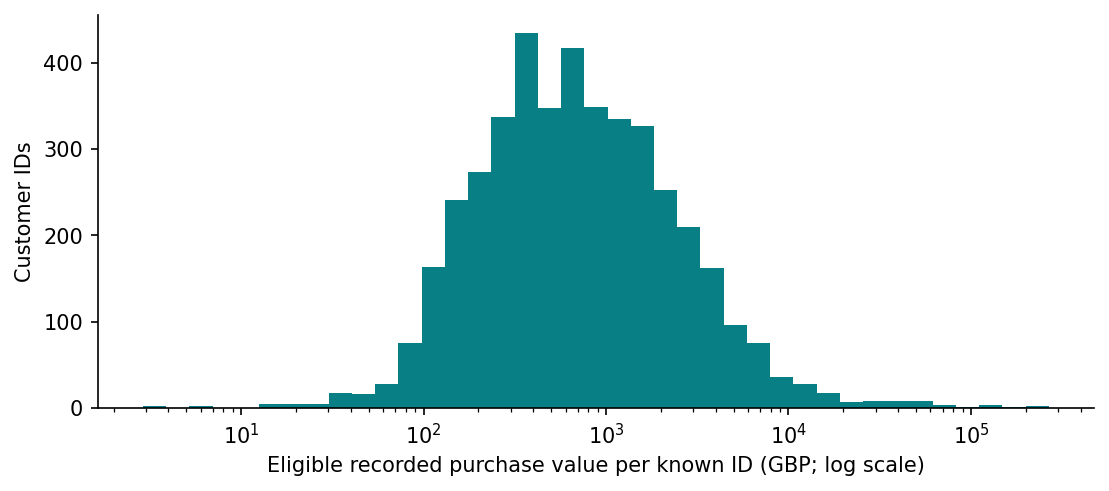

**Frequency Value Relationship**

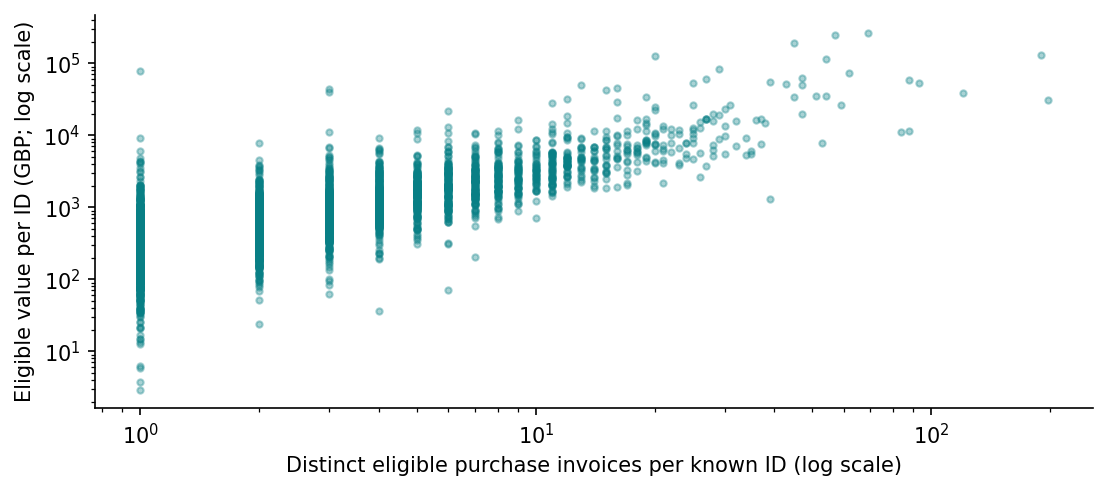

**Concentration Curve**

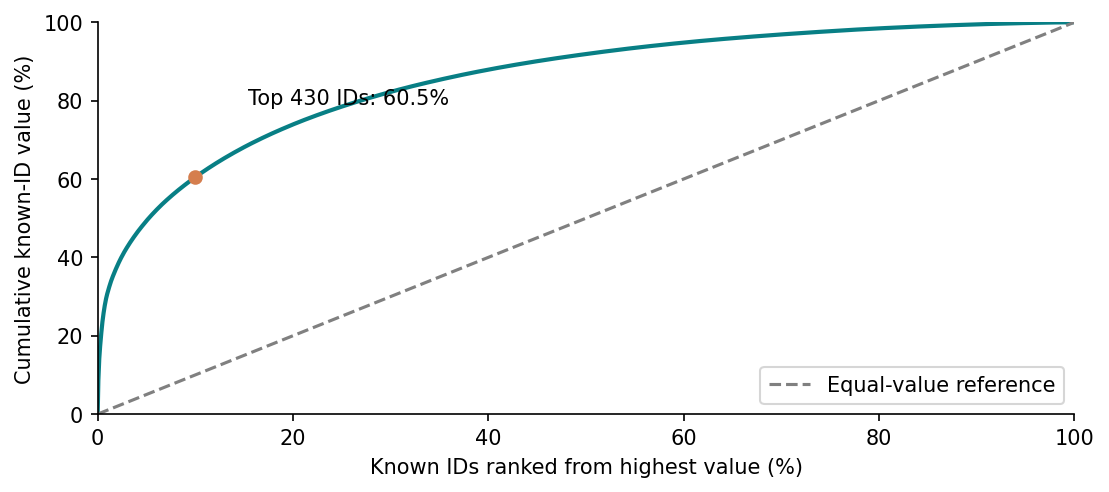

**Monthly Kpi Coverage Population**

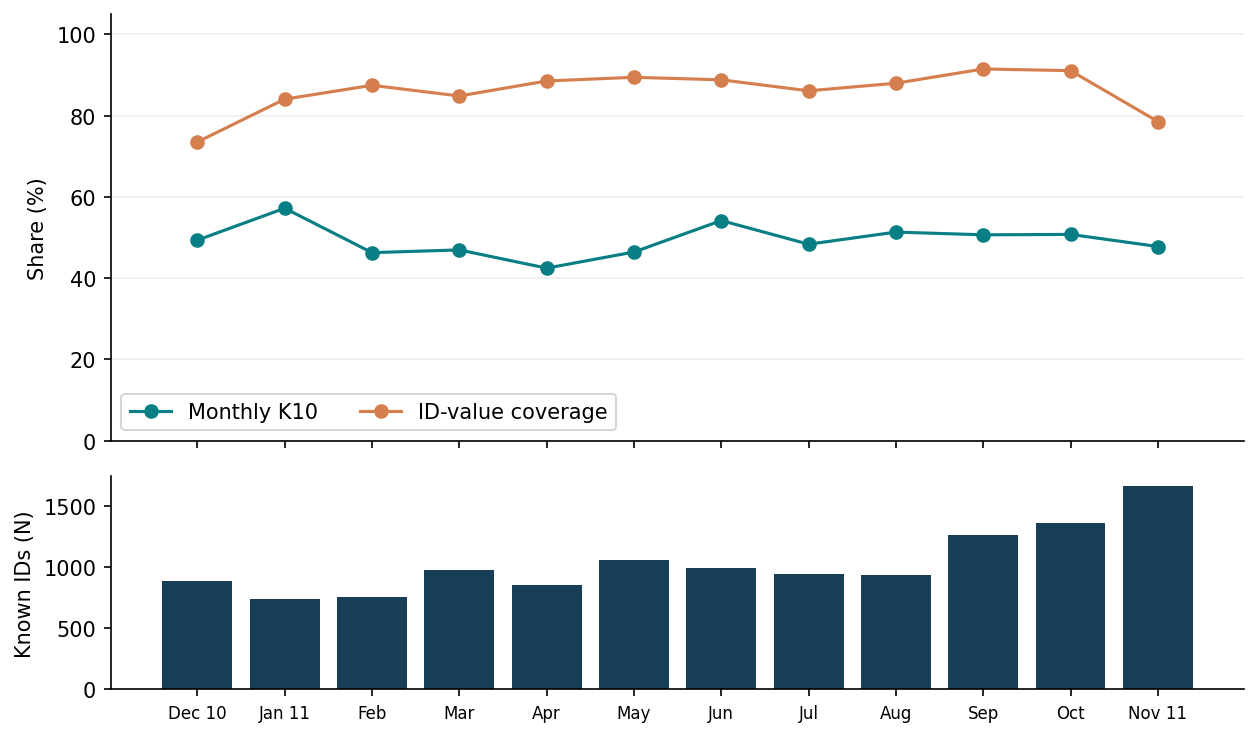

,rule,known_customers,K10_pct,ID_coverage_pct
0,Baseline,4293,60.500139,85.662768
1,Drop exact repeated rows,4293,60.576827,85.631967
2,Five digits only,4273,60.411671,85.677475
3,Remove largest known ID,4292,59.216900,85.252442
4,All positive-priced codes,4297,60.577681,83.698700


In [4]:
stats, monthly, sensitivity = w2.analyze(data)
display(pd.DataFrame([stats['baseline']]))
display(pd.DataFrame([{k:v for k,v in stats.items() if not isinstance(v,dict)}]))
display(monthly[['month','known_customers','top_ids','K10_pct','ID_coverage_pct']])
figure_paths = w2.figures(data, monthly)
for path in figure_paths:
    display(Markdown('**'+path.stem.replace('_',' ').title()+'**'))
    display(Image(filename=str(path)))
display(sensitivity[['rule','known_customers','K10_pct','ID_coverage_pct']])

In [5]:
b=stats['baseline']
display(Markdown(f"""**Interpretation.** The median known-ID value is £{stats['median_customer_value']:,.2f}, compared with a mean of £{stats['mean_customer_value']:,.2f}; large accounts influence the mean. K10 reproduces C1 at {b['K10_pct']:.4f}% and coverage at {b['ID_coverage_pct']:.4f}%. Therefore, the numerical C1 conclusion is retained, conditional on known IDs and the same eligibility rules.

The frequency–value Spearman association is {stats['spearman_frequency_value']:.3f} (Pearson {stats['pearson_frequency_value']:.3f}). More recorded invoices give more opportunities to accumulate value; this does not show that inducing purchases would cause retention or profit. Outliers are not removed just because the distribution is skewed. Sensitivities place K10 between {stats['sensitivity_min_K10']:.2f}% and {stats['sensitivity_max_K10']:.2f}%.

From October to November, K10 changes from {monthly.iloc[-2].K10_pct:.1f}% to {monthly.iloc[-1].K10_pct:.1f}% while coverage changes from {monthly.iloc[-2].ID_coverage_pct:.1f}% to {monthly.iloc[-1].ID_coverage_pct:.1f}%. Changing coverage, customer mix and ranking populations are plausible explanations; we cannot establish that missing IDs caused the K10 change. A single annual cycle cannot establish Christmas seasonality."""))

**Interpretation.** The median known-ID value is £652.80, compared with a mean of £1,917.78; large accounts influence the mean. K10 reproduces C1 at 60.5001% and coverage at 85.6628%. Therefore, the numerical C1 conclusion is retained, conditional on known IDs and the same eligibility rules.

The frequency–value Spearman association is 0.803 (Pearson 0.569). More recorded invoices give more opportunities to accumulate value; this does not show that inducing purchases would cause retention or profit. Outliers are not removed just because the distribution is skewed. Sensitivities place K10 between 59.22% and 60.58%.

From October to November, K10 changes from 50.8% to 47.8% while coverage changes from 91.1% to 78.6%. Changing coverage, customer mix and ranking populations are plausible explanations; we cannot establish that missing IDs caused the K10 change. A single annual cycle cannot establish Christmas seasonality.

## 5. Sampling and representativeness
**Target population:** for the historical question, all relevant purchase activity of the source retailer during the selected year. For any future operational decision, the target would instead be that retailer's recent accounts and processes, which this file cannot represent by assumption.

**Observed population:** the invoice-line records present in the public file within the complete-month extract. These are available administrative records, not a probability sample of UK retailers or all actual purchases. **Final analytical populations:** eligible purchase lines for value/coverage, and identified customer aggregates for K10.

Plausible biases include unrecorded activity in the source system, missing customer identification, an anonymous historical gift retailer with wholesale customers, and provisional product-code exclusions. A precise train/test split does not correct any of these coverage mechanisms.

We sample **25% of distinct invoices within each earliest-invoice-month**, rounding the count to a whole invoice with the fixed seed. We retain all lines of selected invoices. Each invoice within a month has the same inclusion probability; slight rounding and invoice-size variation mean the realized row fraction is not exactly 25%. We do not search for a seed that resembles the full dataset. This samples invoices, not customers: some IDs lose much of their observed history or disappear, changing N and the top decile. The UK comparison uses value by recorded country on each eligible line, including unidentified purchases.

In [6]:
sample, strata, comparison = w2.sample_invoices(data)
display(strata)
display(comparison[['dataset','source_lines','known_customers','top_ids','fraction_source_rows_pct',
                    'K10_pct','K10_pct_difference_pp','ID_coverage_pct','ID_coverage_pct_difference_pp',
                    'UK_value_share_pct','UK_value_share_pct_difference_pp']])
s=comparison.iloc[1]
display(Markdown(f"""**Interpretation.** The sample contains {len(sample):,} rows ({s.fraction_source_rows_pct:.2f}% of the available case) and {s.known_customers:,.0f} known IDs. Sample K10 is {s.K10_pct:.2f}%, a difference of {s.K10_pct_difference_pp:.2f} percentage points. Coverage differs by {s.ID_coverage_pct_difference_pp:.2f} points and UK value share by {s.UK_value_share_pct_difference_pp:.2f} points. These differences describe this one fixed sample; they are not confidence limits or evidence of systematic bias. The smaller customer history changes the estimand's observed population. We therefore retain the complete case for the main descriptive result and use the subsample only to demonstrate sampling effects. Sampling representativeness and train/test information boundaries answer different questions."""))

,month,available_invoices,sampled_invoices,invoice_fraction_pct,available_rows,sample_rows
0,2010-12,2025,506,24.987654,42481,10569
1,2011-01,1476,369,25.000000,35147,8485
2,2011-02,1393,348,24.982053,27707,6971
3,2011-03,1983,496,25.012607,36748,9410
4,2011-04,1744,436,25.000000,29916,7824
5,2011-05,2162,540,24.976873,37030,8830
6,2011-06,2012,503,25.000000,36874,9177
7,2011-07,1927,482,25.012974,39518,10596
8,2011-08,1737,434,24.985607,35284,8261
9,2011-09,2327,582,25.010743,50226,11938


,dataset,source_lines,known_customers,top_ids,fraction_source_rows_pct,K10_pct,K10_pct_difference_pp,ID_coverage_pct,ID_coverage_pct_difference_pp,UK_value_share_pct,UK_value_share_pct_difference_pp
0,Complete available case,516384,4293,430,100.000000,60.500139,0.000000,85.662768,0.000000,84.621508,0.000000
1,Month-stratified invoice sample,130912,2217,222,25.351676,54.008368,-6.491771,85.211919,-0.450849,83.133210,-1.488298


**Interpretation.** The sample contains 130,912 rows (25.35% of the available case) and 2,217 known IDs. Sample K10 is 54.01%, a difference of -6.49 percentage points. Coverage differs by -0.45 points and UK value share by -1.49 points. These differences describe this one fixed sample; they are not confidence limits or evidence of systematic bias. The smaller customer history changes the estimand's observed population. We therefore retain the complete case for the main descriptive result and use the subsample only to demonstrate sampling effects. Sampling representativeness and train/test information boundaries answer different questions.

## 6. Chronological holdout and train-only preprocessing
The decision moment is a review **after month-end**, when recorded invoices up to the cut-off are available. We preserve the direction past → later. Training uses December–July, validation August–September and test October–November. Eight calendar months do not imply 80% of rows; year-end activity is larger. These dates were chosen before W2 result inspection and are not optimized from the test.

This is a descriptive robustness design, not a predictive accuracy experiment. W1/C1 already examined the test months. The held partitions are separate by source row and invoice; they are not statistically independent customer populations. Customer recurrence is intentional for reviewing existing accounts over time. Generalization to entirely new customers would require grouped validation instead. We report customer overlap so it cannot be mistaken for independence.

The partitions are constructed from the **complete case, not the sampling demonstration**. All groups, including unidentified purchases and records outside the value measure, are saved. Comparison of the main KPI remains monthly; we do not interpret totals over an eight-month period and two-month periods as directly comparable.

For the preprocessing demonstration, an eligible invoice's completed purchase value is available at a later month-end review. We apply log1p and fit StandardScaler on training invoices only; validation and test receive the unchanged rule. This could support a future order-size descriptor. It would leak information if used to predict that same invoice's value before it occurred. Standardization is not needed to compute K10 and does not replace GBP in the KPI.

In [7]:
splits, split_summary, overlap = w2.make_splits(data)
display(split_summary)
display(overlap)
preprocessing_table, preprocessing_parameters = w2.preprocess(splits)
display(pd.DataFrame([preprocessing_parameters]))
display(preprocessing_table)
print('Validation inspected after the train-only fit; test transformed afterward without refitting.')
print('No model, target, model selection or predictive performance score is computed.')

,split,first,last,rows,row_fraction_pct,invoices,known_ids_raw,eligible_purchase_lines,eligible_known_ids
0,train,2010-12-01 08:26:00,2011-07-31 16:04:00,285421,55.273014,14722,3193,275701,3145
1,validation,2011-08-01 08:30:00,2011-09-30 17:22:00,85510,16.559382,4064,1817,83113,1769
2,test,2011-10-02 10:32:00,2011-11-30 17:42:00,145453,28.167604,6099,2446,141717,2405


,left,right,unit,overlap_count,interpretation
0,train,validation,source_rows,0,Must be zero
1,train,validation,invoices,0,Must be zero
2,train,validation,known_customer_ids,1352,Allowed: same-account later-period scope
3,train,validation,exact_source_record_hashes,0,Must be zero; duplicates include invoice and timestamp
4,train,test,source_rows,0,Must be zero
5,train,test,invoices,0,Must be zero
6,train,test,known_customer_ids,1566,Allowed: same-account later-period scope
7,train,test,exact_source_record_hashes,0,Must be zero; duplicates include invoice and timestamp
8,validation,test,source_rows,0,Must be zero
9,validation,test,invoices,0,Must be zero


,feature,fit_partition,fitted_invoice_count,mean,scale,refit_on_validation_or_test,parameter_invariance_verified,K10_uses_original_GBP
0,log1p(invoice_value_gbp),train,11040,5.508743,1.194544,False,True,True


,split,invoices,mean_log_value,mean_scaled_value,sd_scaled_value_ddof0
0,train,11040,5.508743,-6.159324e-16,1.000000
1,validation,3157,5.682812,1.457204e-01,0.959134
2,test,4756,5.612792,8.710356e-02,0.967170


Validation inspected after the train-only fit; test transformed afterward without refitting.
No model, target, model selection or predictive performance score is computed.


**Validation decision.** We inspect whether validation can be transformed under the fixed rule and whether the train-fitted parameters remain unchanged. We keep the prespecified transformation: there is no predictive objective or tuning criterion in W2. The same rule is then applied to test without refit. Nonzero validation/test means are expected under changed invoice distributions; they do not justify refitting on the test. A genuinely later dataset, not previously explored, is still needed before claiming prospective validity.

## 7. Contextual leakage audit
The table distinguishes an observed overlap, an actual information violation and a hypothetical future misuse. A shared CustomerID is not automatically inappropriate for the stated same-account time scenario, but it precludes a claim of independent new-customer evaluation. Target-derived leakage is assessed conditionally because the present project has no predictive target.

In [8]:
leakage = w2.leakage_audit(data, overlap, preprocessing_parameters)
display(leakage)

,risk,status,dataset_evidence,potential_consequence,mitigation
0,Future full-case customer totals/rank,present in prior artifacts,C1 aggregates span Dec 2010–Nov 2011; not W2 pre-cutoff features,Would reveal later purchases before review date,Rebuild invoice/period aggregates from rows available at that cut-off; exclude full-year rank from fe...
1,Repeated customer accounts,present,1566 known IDs occur in both train and test,Invalid new-customer independence claim; global customer aggregation could leak future history,Allow repeated IDs for same-account time review; disclose dependence; no full-case profile reuse
2,Duplicated event lines across partitions,absent across chosen partitions,4989 extra exact repeats within source; zero record-hash and invoice overlap across partitions,Random line splitting could put copies or sibling invoice lines on both sides,Partition by recorded time and verify invoice/record-hash boundaries; retain baseline repeats with se...
3,Preprocessing learned on validation/test,absent in W2,Scaler fit on 11040 train invoices; parameters unchanged after transformations,Full-data mean/scale would let held data influence fitted rule,Fit once on train; transform validation/test; export fit parameters and invariance checks
4,Target-derived variables in hypothetical prediction,uncertain for future use; no target/model in W2,"Invoice value, period value and K10 use completed purchases",Predicting the same purchase value from its total/rank would be circular,Define any future outcome and horizon first; use only prior-cutoff information; no accuracy claim here
5,Prior full-case exploration / analyst leakage,present,"W1/C1 inspected all twelve months, including Oct–Nov; source snapshots retained",Current test cannot be described as untouched prospective evidence,Prespecify W2 transformations; treat as descriptive robustness; collect a genuinely later period befo...
6,Linked external tables,absent / not applicable,Single UCI source; W2 performs no external join,Future joins could leak later customer states or create duplicate rows,"No forced join; require as-of keys, cardinality and match checks before future integration"


## 8. Management interpretation and next step
The summary below is generated from verified outputs and has 120–180 words. Observed facts, scope assumptions and proposed managerial actions remain distinct.

In [9]:
results = w2.finalize(stats, quality_details, comparison, preprocessing_parameters, quality, split_summary)
summary = w2.management_summary(stats, comparison, quality_details)
print('Management summary word count:',len(summary.split()))
display(Markdown(summary))
print('Verified outputs:', len(json.loads((ROOT/'evidence/artifact_manifest.json').read_text())))

Management summary word count: 141


Our historical account-review question and K10 definition remain unchanged from C1. The complete case still contains 4,293 identifiable customers: the highest-value 10% account for 60.5% of known purchase value, while IDs cover 85.7% of eligible value. W2 adds explicit validation, a month-stratified invoice sample and chronological development, validation and test partitions. We retained 43 invoices with multiple timestamps and 8 IDs with multiple country labels, documenting their interpretation rather than overwriting records. The sample contains 25.4% of source lines and yields K10 of 54.0%, illustrating the effect of observing fewer invoices per customer. Train-only preprocessing prevents held periods from determining the fitted scale. However, missing IDs, provisional product codes and prior exploration of all periods still limit generalization. We recommend reviewing major accounts and ID capture together, then obtaining recent transactions and verified identity/code definitions before operational use or prospective evaluation.

Verified outputs: 29


## 9. References, AI use and traceability
- Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository. DOI: https://doi.org/10.24432/C5BW33. Dataset and dictionary: https://archive.ics.uci.edu/dataset/352/online-retail. Source licence: CC BY 4.0. The original retrieval/check is recorded in the preserved manifest; no new download is claimed.
- Fontecilla, T. (2026). *Workshop 2: From Exploratory Analysis to Credible Validation*, student brief and rubric supplied in the course workspace.
- Course notebooks: *Validation, Leakage and Reproducible Pipelines*; *Guided Validation Case*; *Sampling, Regression and Classification*. Consulted locally for sampling/split distinctions and train-only transformations. Teacher materials are not redistributed in this repository.
- W1/C1 self-contained reports and executed notebooks: `assessments/W1/` and `assessments/C1/`. Their original text is preserved as historical submission evidence, including its stated uncertainties.

**AI assistance and verification.** OpenAI Codex assisted with code, report/notebook drafts and layout. The team's implementation request fixed the same KPI, seed, invoice sampling and chronological periods. Accepted suggestions include explicit flags, period-specific aggregates and an exported check table. Unsupported claims about price-zero reasons, customer loyalty, net revenue or a pristine holdout are excluded. Executable assertions and automated reruns check consequential suggestions against the source; those are automated checks, not claims that a student personally performed each verification. The team remains responsible for reviewing, understanding and defending the submitted work. No individual contribution or instructor comment has been invented.

The source extract is unchanged. `evidence/protocol.json` records analytical assumptions; `data/processed/` contains checkable tables, actual samples and prepared lines; `data/splits/` contains actual partition files. The README provides reproduction instructions and the final submission identifies the Git commit and tag. The supplemental LaTeX report uses these same generated outputs.